In [5]:
pip install openpyxl

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


   Customer ID  Annual Income  Spending Score
0            1             15              39
1            2             16              81
2            3             17               6
3            4             18              77
4            5             19              40
    Customer ID  Annual Income  Spending Score  Cluster
0             1             15              39        3
1             2             16              81        0
2             3             17               6        3
3             4             18              77        0
4             5             19              40        3
5             6             20              76        0
6             7             22               6        3
7             8             23              94        0
8             9             24              35        3
9            10             25              82        0
10           11             35              14        3
11           12             36              75      

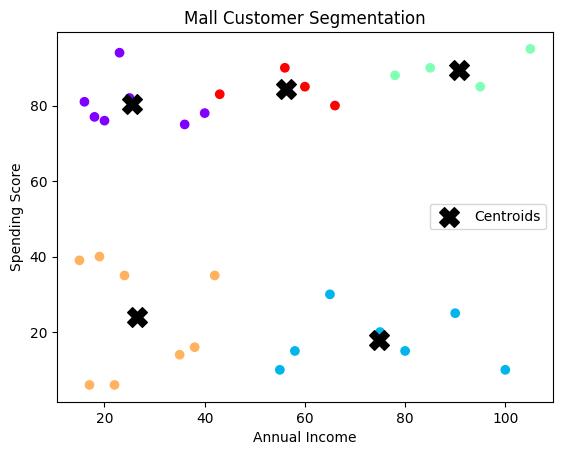

In [2]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# Load dataset
df = pd.read_excel("mall_customers.xlsx")

# Display dataset
print(df.head())

# Select features
X = df[['Annual Income', 'Spending Score']]

# Apply K-Means
kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)



In [4]:
kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)
# Train model
kmeans.fit(X)

# Add cluster labels
df['Cluster'] = kmeans.labels_

# Display results
print(df)

    Customer ID  Annual Income  Spending Score  Cluster
0             1             15              39        3
1             2             16              81        0
2             3             17               6        3
3             4             18              77        0
4             5             19              40        3
5             6             20              76        0
6             7             22               6        3
7             8             23              94        0
8             9             24              35        3
9            10             25              82        0
10           11             35              14        3
11           12             36              75        0
12           13             38              16        3
13           14             40              78        0
14           15             42              35        3
15           16             43              83        4
16           17             55              10  

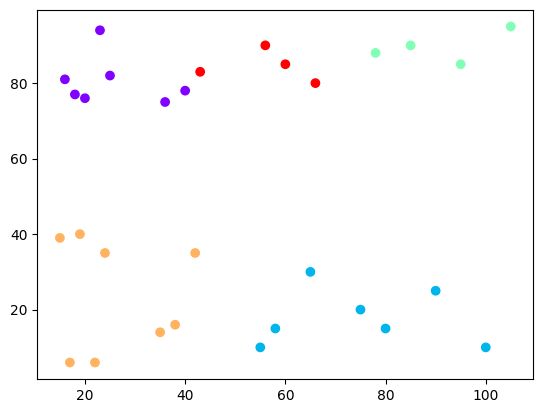

In [5]:
# Visualize clusters
plt.scatter(
    X['Annual Income'],
    X['Spending Score'],
    c=df['Cluster'],
    cmap='rainbow'
)

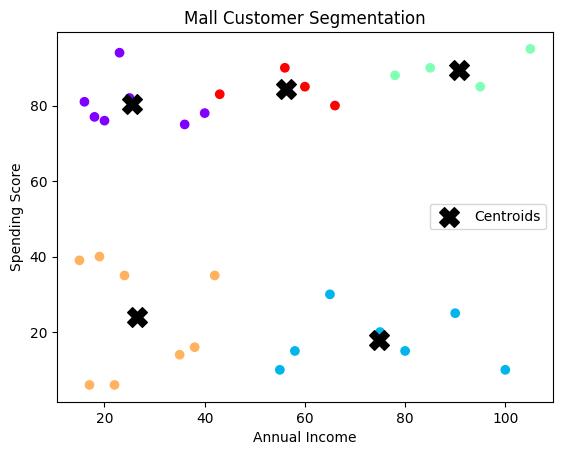

In [7]:
# Display centroids
plt.scatter(
    X['Annual Income'],
    X['Spending Score'],
    c=df['Cluster'],
    cmap='rainbow'
)
centroids = kmeans.cluster_centers_

plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    color='black',
    marker='X',
    s=200,
    label='Centroids'
)

plt.xlabel('Annual Income')
plt.ylabel('Spending Score')
plt.title('Mall Customer Segmentation')
plt.legend()
plt.show()